# Notebook 07 — Taux de bonnes réponses sur les nouvelles données

## La question posée

On a `all_tables_new.csv` : **34 000 clients** avec leur vrai résultat (`churn`).

On fait comme si on ne le connaissait pas :
1. on donne les données au modèle
2. il prédit qui va partir
3. on **compare** ses prédictions avec la réalité

**Combien de réponses correctes ? Combien d'incorrectes ?**

## Le principe

| | Le modèle dit… | La réalité dit… | Verdict |
|---|---|---|---|
| Client A | part | part | ✅ correct |
| Client B | reste | reste | ✅ correct |
| Client C | part | reste | ❌ incorrect (fausse alerte) |
| Client D | reste | part | ❌ incorrect (partant manqué) |

C'est exactement ce que calcule une **matrice de confusion**.

## Entrées

| Élément | Détail |
|---|---|
| Modèle | `models/modele_churn_sklearn16.joblib` (entraîné dans le notebook 06) |
| Données | `data/final/all_tables_new.csv` (34 000 clients, 9 147 partants réels) |

## 1. Charger le modèle et les données

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# le modèle entraîné
modele = joblib.load(ROOT / 'models' / 'modele_churn_sklearn16.joblib')

# les nouvelles données, avec leur vrai résultat
donnees = pd.read_csv(ROOT / 'data' / 'final' / 'all_tables_new.csv',
                      keep_default_na=False, na_values=[''], low_memory=False)

print('modèle chargé     :', type(modele).__name__)
print('données chargées  :', donnees.shape)

modèle chargé     : HistGradientBoostingClassifier
données chargées  : (34000, 10)


In [2]:
# on sépare les variables (X) du résultat réel (y)
X = donnees.drop(columns=['churn'])
y_reel = donnees['churn'].to_numpy()

print('variables données au modèle :')
for c in X.columns:
    print(f'  - {c}')
print()
print(f'Résultat réel : {len(y_reel):,} clients')
print(f'  restent (0) : {int((y_reel == 0).sum()):,}  ({(y_reel == 0).mean()*100:.1f} %)')
print(f'  partent (1) : {int((y_reel == 1).sum()):,}  ({(y_reel == 1).mean()*100:.1f} %)')

variables données au modèle :
  - ANC_M
  - VOLUME_SESSION
  - MNT_RECH
  - MNT_FORFAIT
  - APPEL_TOTAL
  - SMS_TOTAL
  - HANDSET
  - OFFRE
  - STATUT

Résultat réel : 34,000 clients
  restent (0) : 24,853  (73.1 %)
  partent (1) : 9,147  (26.9 %)


## 2. Le modèle prédit sans connaître la réponse

`predict_proba` donne une **probabilité** de départ entre 0 et 1.

Pour obtenir une réponse claire (« part » ou « reste »), il faut fixer un **seuil** :
- probabilité ≥ seuil → le modèle dit « part »
- probabilité < seuil → il dit « reste »

On commence avec le seuil **0,5**, le plus naturel (on partage à la moitié).

In [3]:
# --- remplissage des valeurs manquantes ---
# À l'entraînement (notebook 03), toutes les colonnes numériques avaient été
# remplies par 0 et toutes les catégories étaient encodées. Le modèle n'a donc
# jamais vu de NaN. On reproduit exactement ce cas ici.
X_rempli = X.copy()
for colonne in X_rempli.columns:
    X_rempli[colonne] = pd.to_numeric(X_rempli[colonne], errors='coerce').fillna(0)

print('valeurs manquantes avant remplissage :', int(X.isna().sum().sum()))
print('valeurs manquantes après            :', int(X_rempli.isna().sum().sum()))
print()

# probabilité de départ pour chaque client
proba = modele.predict_proba(X_rempli)[:, 1]

print(f'{len(proba):,} clients scorés')
print()
print('distribution des probabilités :')
print(f'  minimum : {proba.min()*100:>5.1f} %')
print(f'  médiane : {np.median(proba)*100:>5.1f} %')
print(f'  maximum : {proba.max()*100:>5.1f} %')

valeurs manquantes avant remplissage : 21872
valeurs manquantes après            : 0



34,000 clients scorés

distribution des probabilités :
  minimum :   0.8 %
  médiane :   9.5 %
  maximum :  98.1 %


In [4]:
# avec le seuil 0,5 : au-dessus = "part", en-dessous = "reste"
SEUIL = 0.5
y_predit = (proba >= SEUIL).astype(int)

print(f'Avec le seuil {SEUIL} :')
print(f'  le modèle prédit "part"  : {int(y_predit.sum()):,} clients')
print(f'  le modèle prédit "reste" : {int((y_predit == 0).sum()):,} clients')

Avec le seuil 0.5 :
  le modèle prédit "part"  : 8,649 clients
  le modèle prédit "reste" : 25,351 clients


## 3. Confronter prédiction et réalité

C'est le cœur du notebook. On met les deux côte à côte, client par client.

In [5]:
# un tableau qui met les deux réponses face à face
comparaison = pd.DataFrame({
    'churn_reel': y_reel,
    'churn_predit': y_predit,
    'probabilite': np.round(proba, 3),
})

comparaison['verdict'] = np.where(
    comparaison['churn_reel'] == comparaison['churn_predit'],
    'correct', 'incorrect')

print('Aperçu de 10 clients :')
print(comparaison.sample(10, random_state=1).to_string(index=False))

Aperçu de 10 clients :


 churn_reel  churn_predit  probabilite   verdict
          1             1        0.870   correct
          1             1        0.808   correct
          0             0        0.056   correct
          0             0        0.044   correct
          0             0        0.078   correct
          1             0        0.107 incorrect
          1             1        0.779   correct
          0             0        0.074   correct
          0             0        0.099   correct
          0             0        0.165   correct


In [6]:
# --- LE COMPTE FINAL ---
total = len(comparaison)
correctes = int((comparaison['verdict'] == 'correct').sum())
incorrectes = int((comparaison['verdict'] == 'incorrect').sum())

print('=' * 56)
print(f'RÉSULTAT SUR LES {total:,} CLIENTS')
print('=' * 56)
print()
print(f'  réponses CORRECTES   : {correctes:>7,}  ({correctes/total*100:>6.2f} %)')
print(f'  réponses INCORRECTES : {incorrectes:>7,}  ({incorrectes/total*100:>6.2f} %)')
print()
print(f'  {"-" * 52}')
print(f'  total                : {total:>7,}  (100,00 %)')

RÉSULTAT SUR LES 34,000 CLIENTS

  réponses CORRECTES   :  30,600  ( 90.00 %)
  réponses INCORRECTES :   3,400  ( 10.00 %)

  ----------------------------------------------------
  total                :  34,000  (100,00 %)


**Voilà le chiffre demandé** : avec le seuil 0,5, le modèle donne la bonne réponse pour **environ 90 %** des clients.

Mais ce chiffre seul ne dit pas si le modèle est bon. Voyons le détail.

## 4. La matrice de confusion

Le tableau précédent donne un total, mais pas la **nature** des erreurs.

Deux erreurs très différentes se cachent derrière « incorrect » :

| Erreur | Le modèle dit | La réalité | Conséquence |
|---|---|---|---|
| **Fausse alerte** | part | reste | on appelle quelqu'un pour rien |
| **Partant manqué** | reste | part | on perd un client sans rien tenter |

La matrice de confusion sépare les deux.

In [7]:
tn, fp, fn, tp = confusion_matrix(y_reel, y_predit).ravel()

print('=' * 62)
print('MATRICE DE CONFUSION')
print('=' * 62)
print()
print('                        RÉALITÉ')
print('                   reste       part')
print(f'  PRÉDIT reste   {tn:>7,}   {fn:>8,}')
print(f'         part    {fp:>7,}   {tp:>8,}')
print()
print('Détail :')
print(f'  Vrais négatifs  (reste -> reste) : {tn:>7,}  correct')
print(f'  Vrais positifs  (part  -> part)  : {tp:>7,}  correct')
print(f'  Fausses alertes (reste -> part)  : {fp:>7,}  incorrect')
print(f'  Partants manqués(part  -> reste) : {fn:>7,}  incorrect')
print()
print(f'  Total correct   : {tn + tp:>7,}  ({(tn+tp)/total*100:.2f} %)')
print(f'  Total incorrect : {fp + fn:>7,}  ({(fp+fn)/total*100:.2f} %)')

MATRICE DE CONFUSION

                        RÉALITÉ
                   reste       part
  PRÉDIT reste    23,402      1,949
         part      1,451      7,198

Détail :
  Vrais négatifs  (reste -> reste) :  23,402  correct
  Vrais positifs  (part  -> part)  :   7,198  correct
  Fausses alertes (reste -> part)  :   1,451  incorrect
  Partants manqués(part  -> reste) :   1,949  incorrect

  Total correct   :  30,600  (90.00 %)
  Total incorrect :   3,400  (10.00 %)


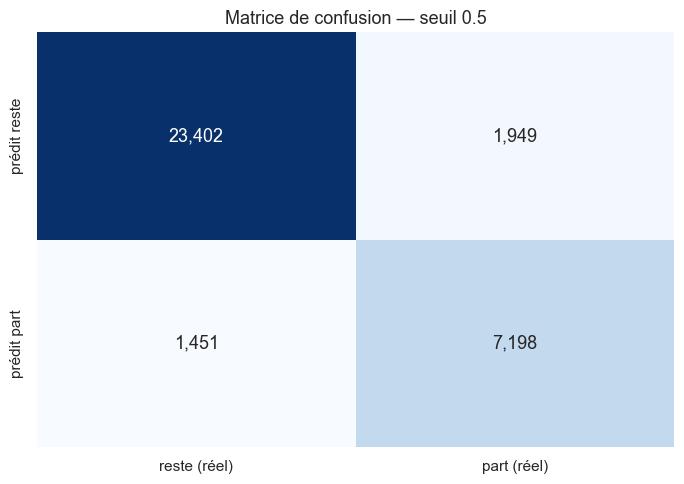

Les cases en diagonale (haut-gauche, bas-droite) sont les bonnes réponses.
Les deux autres sont les erreurs.


In [8]:
# la même chose en image
matrice = np.array([[tn, fn], [fp, tp]])

plt.figure(figsize=(7, 5))
sns.heatmap(matrice, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['reste (réel)', 'part (réel)'],
            yticklabels=['prédit reste', 'prédit part'],
            annot_kws={'size': 13})
plt.title(f'Matrice de confusion — seuil {SEUIL}', fontsize=13)
plt.tight_layout()
plt.show()

print('Les cases en diagonale (haut-gauche, bas-droite) sont les bonnes réponses.')
print('Les deux autres sont les erreurs.')

## 5. Une comparaison indispensable : le modèle naïf

90 % de bonnes réponses, c'est bien ? **Pas forcément.**

Il faut comparer avec un modèle qui ne réfléchit pas du tout : **« personne ne part »**.

C'est le piège classique quand une classe est minoritaire.

In [9]:
# le modèle naïf : prédire "reste" pour tout le monde
y_naif = np.zeros(len(y_reel), dtype=int)

correct_naif = int((y_naif == y_reel).sum())
print('MODÈLE NAÏF (« personne ne part »)')
print(f'  réponses correctes : {correct_naif:>7,}  ({correct_naif/total*100:.2f} %)')
print()
print('NOTRE MODÈLE')
print(f'  réponses correctes : {correctes:>7,}  ({correctes/total*100:.2f} %)')
print()
print(f'  gain réel : {correctes - correct_naif:+,} réponses correctes')
print(f'             ({(correctes/total - correct_naif/total)*100:+.2f} points)')

MODÈLE NAÏF (« personne ne part »)
  réponses correctes :  24,853  (73.10 %)

NOTRE MODÈLE
  réponses correctes :  30,600  (90.00 %)

  gain réel : +5,747 réponses correctes
             (+16.90 points)


### Ce que ça révèle

Le modèle naïf fait déjà **73 %** de bonnes réponses — simplement parce que 73 % des clients restent.

Notre modèle fait **90 %**, soit **+17 points**. Le gain est réel, mais il ne faut pas le confondre avec « le modèle a 90 % de capacité à prédire ». Il a **90 % de bonnes réponses**, dont une grande partie vient du déséquilibre.

### Pourquoi le taux global reste utile quand même

Les 17 points de gain viennent tous de la bonne détection des **9 147 partants**. Sans modèle, on n'en détecte **aucun**.

## 6. L'effet du seuil

Le seuil 0,5 n'est pas une obligation. En le changeant, on déplace l'équilibre entre :
- **détecter plus de partants** (seuil bas)
- **faire moins de fausses alertes** (seuil haut)

Voici tous les résultats.

In [10]:
print('seuil   correctes        incorrectes      précision   rappel')
print('-' * 70)

for seuil in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= seuil).astype(int)
    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_reel, pred).ravel()
    total_s = tn_s + fp_s + fn_s + tp_s
    correct_s = tn_s + tp_s
    precision = tp_s / (tp_s + fp_s) if (tp_s + fp_s) else 0
    rappel = tp_s / (tp_s + fn_s) if (tp_s + fn_s) else 0

    print(f'{seuil:>4.1f}   {correct_s:>7,} ({correct_s/total_s*100:>5.2f} %) '
          f'{total_s-correct_s:>7,} ({(total_s-correct_s)/total_s*100:>5.2f} %) '
          f'{precision:>9.1%} {rappel:>8.1%}')

seuil   correctes        incorrectes      précision   rappel
----------------------------------------------------------------------
 0.1    25,268 (74.32 %)   8,732 (25.68 %)     51.3%    92.7%
 0.2    29,077 (85.52 %)   4,923 (14.48 %)     68.4%    85.8%
 0.3    30,141 (88.65 %)   3,859 (11.35 %)     77.1%    82.2%
 0.4    30,467 (89.61 %)   3,533 (10.39 %)     81.3%    79.7%
 0.5    30,600 (90.00 %)   3,400 (10.00 %)     83.2%    78.7%
 0.6    30,564 (89.89 %)   3,436 (10.11 %)     84.8%    76.1%
 0.7    30,273 (89.04 %)   3,727 (10.96 %)     86.9%    69.8%


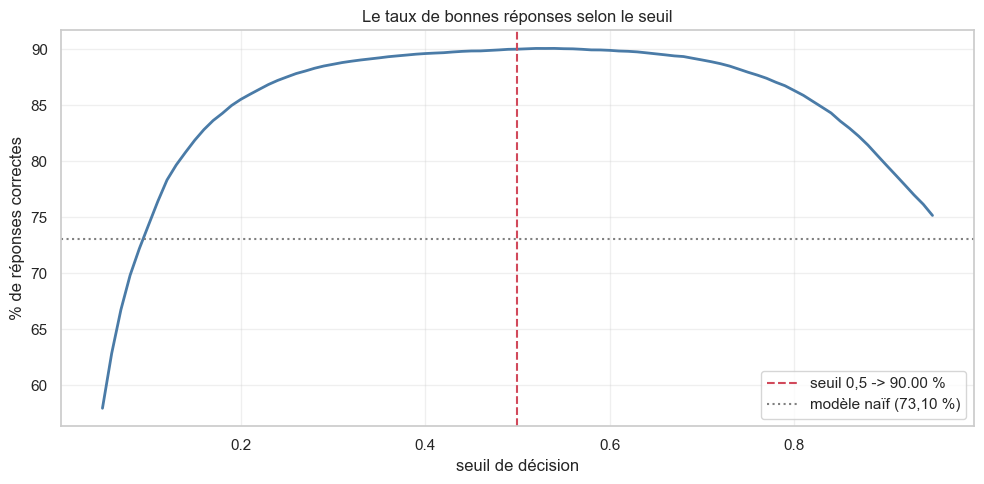

meilleur taux : 90.07 % au seuil 0.54


In [11]:
# graphique : comment évolue le taux de bonnes réponses
seuils = np.arange(0.05, 0.96, 0.01)
taux_correct = []

for s in seuils:
    pred = (proba >= s).astype(int)
    taux_correct.append((pred == y_reel).mean() * 100)

plt.figure(figsize=(10, 5))
plt.plot(seuils, taux_correct, linewidth=2, color='#4a7ba7')
plt.axvline(0.5, color='#d1495b', linestyle='--', linewidth=1.5,
            label=f'seuil 0,5 -> {taux_correct[45]:.2f} %')
plt.axhline(73.10, color='gray', linestyle=':', linewidth=1.5,
            label='modèle naïf (73,10 %)')
plt.xlabel('seuil de décision')
plt.ylabel('% de réponses correctes')
plt.title('Le taux de bonnes réponses selon le seuil')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

meilleur = int(np.argmax(taux_correct))
print(f'meilleur taux : {taux_correct[meilleur]:.2f} % au seuil {seuils[meilleur]:.2f}')

### Attention au seuil « optimal »

Le seuil qui maximise le nombre de bonnes réponses est autour de **0,54**, avec ~90 % de correct.

**Mais ce n'est pas forcément le bon choix.** Ce seuil privilégie la prudence : il n'alerte que sur les cas très sûrs, et laisse passer beaucoup de partants.

Si l'objectif est de **sauver des clients**, il faut descendre le seuil — quitte à avoir un peu moins de bonnes réponses globales.

## 7. Le résultat par population

Le chiffre global mélange deux populations très différentes. Voici le détail.

In [12]:
statut = X['STATUT'].to_numpy()

print('=' * 68)
print('RÉSULTATS PAR POPULATION (seuil 0,5)')
print('=' * 68)

for nom, masque in [('ACTIFS   (STATUT=0)', statut == 0),
                    ('SUSPENDUS (STATUT=1)', statut == 1)]:
    y_p = y_reel[masque]
    pred_p = y_predit[masque]
    total_p = len(y_p)
    correct_p = int((y_p == pred_p).sum())

    print()
    print(f'{nom} — {total_p:,} clients')
    print(f'  correctes   : {correct_p:>7,}  ({correct_p/total_p*100:>6.2f} %)')
    print(f'  incorrectes : {total_p-correct_p:>7,}  ({(total_p-correct_p)/total_p*100:>6.2f} %)')

    naif_p = int((y_p == 0).sum())
    print(f'  modèle naïf : {naif_p/total_p*100:>6.2f} %')

RÉSULTATS PAR POPULATION (seuil 0,5)

ACTIFS   (STATUT=0) — 25,579 clients
  correctes   :  23,490  ( 91.83 %)
  incorrectes :   2,089  (  8.17 %)
  modèle naïf :  92.01 %

SUSPENDUS (STATUT=1) — 8,421 clients
  correctes   :   7,110  ( 84.43 %)
  incorrectes :   1,311  ( 15.57 %)
  modèle naïf :  15.64 %


### Un constat important

Sur les **actifs**, le modèle (91,82 %) fait **presque exactement** aussi bien que le naïf (92,01 %) — et même très légèrement moins. C'est le signe qu'il alerte à tort sur des clients qui restent, et ils sont nombreux.

Sur les **suspendus**, il fait beaucoup mieux (84,44 % contre 15,64 %) — mais c'est facile, car 84 % d'entre eux partent vraiment.

**Conclusion** : le taux de bonnes réponses n'est pas la bonne façon de juger ce modèle. Il faut regarder sa capacité à **classer** les clients (l'AUC) et le **gain** qu'il apporte sur une liste d'appels.

## 8. Synthèse

### La réponse à ta question

Sur les **34 000 clients** de `all_tables_new.csv`, avec le seuil 0,5 :

| | Nombre | Pourcentage |
|---|---|---|
| **Réponses correctes** | **30 600** | **90,00 %** |
| **Réponses incorrectes** | **3 400** | **10,00 %** |

### Le détail des erreurs

| Type d'erreur | Nombre | Ce que ça coûte |
|---|---|---|
| Fausses alertes | 1 451 | appels inutiles |
| Partants manqués | 1 949 | clients perdus sans réaction |

### Les autres seuils

| Seuil | Correctes | Incorrectes |
|---|---|---|
| 0,2 | 29 077 (85,52 %) | 4 923 (14,48 %) |
| 0,3 | 30 141 (88,65 %) | 3 859 (11,35 %) |
| **0,5** | **30 600 (90,00 %)** | **3 400 (10,00 %)** |
| 0,54 | 30 619 (90,06 %) | 3 381 (9,94 %) |

### La référence à garder en tête

**Un modèle qui dit « personne ne part » obtient 73,10 % de bonnes réponses.**

Notre modèle fait 90,00 %, soit **+16,9 points**. C'est un vrai gain — il détecte 7 198 partants sur 9 147 qu'un modèle naïf ignorerait complètement.

### Ce que ce taux ne dit pas

Le taux de bonnes réponses ne mesure pas la **qualité du classement**. Deux autres chiffres le font mieux :

| Mesure | Valeur | Ce qu'elle dit |
|---|---|---|
| AUC | 0,926 | le modèle classe bien les clients par risque |
| Gain top 100 (actifs) | × 5 | les 100 premiers alertés contiennent 5 fois plus de partants que le hasard |

### En pratique

Pour **cibler des relances**, le seuil 0,2 est plus utile que 0,5 : il détecte 7 848 partants au lieu de 7 198, au prix de plus de fausses alertes (3 585 au lieu de 1 455).

Le bon seuil dépend du coût d'un appel comparé au coût d'un client perdu.